In [16]:
from dataloader import load_all_data
import pandas as pd
import numpy as np
import scipy
from scipy import stats
import tqdm

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
import seaborn as sns
sns.set_theme(style='ticks')
from statannotations.Annotator import Annotator

In [17]:
colors = ['#c26f6d', '#d9a6a4', '#f2dfdd', '#e4e5eb', '#aab8d0', '#6e90bf']
interfaces = {
    'pointwise':        'UI1',
    'pairwise':         'UI2',
    'listwise-rating':  'UI3',
    'listwise-notie':   'UI4',
    'listwise-cantie':  'UI5',
    'listwise-ranking': 'UI6',
}

df_begins, df_all, df_finishs, df_demographic = load_all_data()

pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking
pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking


In [18]:
df_progress = df_all[['userID', 'domain', 'taskID', 'interface', 'iteration', 'rating', 'skip', 'parameters', 'options']]
df_progress

,userID,domain,taskID,interface,iteration,rating,skip,parameters,options
0,P330,text,3,pointwise,1,83,False,"[{'reduction_ratio': 0.1924789845943451, 'top_...",[text/1/pointwise/P330-630...
1,P330,text,3,pointwise,2,87,False,"[{'reduction_ratio': 0.7346476912498474, 'top_...",[text/1/pointwise/P330-630...
2,P330,text,3,pointwise,3,71,False,"[{'reduction_ratio': 0.9412690997123718, 'top_...",[text/1/pointwise/P330-630...
3,P330,text,3,pointwise,4,81,False,"[{'reduction_ratio': 0.5664541125297546, 'top_...",[text/1/pointwise/P330-630...
4,P330,text,3,pointwise,5,81,False,"[{'reduction_ratio': 0.34385254979133606, 'top...",[text/1/pointwise/P330-630...
...,...,...,...,...,...,...,...,...,...
8930,P149,image,2,listwise-ranking,2,"[{'id': 0, 'rating': 'Excellent', 'timestamp':...",False,"[{'brightness': 0.571182370185852, 'contrast':...",[image/1/listwise-ranking/60b63cc430b27a19351d...
8931,P149,image,2,listwise-ranking,3,"[{'id': 1, 'rating': 'Fair', 'timestamp': 1670...",False,"[{'brightness': 0.629599392414093, 'contrast':...",[image/1/listwise-ranking/60b63cc430b27a19351d...
8932,P149,image,2,listwise-ranking,4,"[{'id': 0, 'rating': 'I don't know', 'timestam...",False,"[{'brightness': 0.4798765480518341, 'contrast'...",[image/1/listwise-ranking/60b63cc430b27a19351d...
8933,P149,image,2,listwise-ranking,5,"[{'id': 2, 'rating': 'Excellent', 'timestamp':...",False,"[{'brightness': 0.2839641869068146, 'contrast'...",[image/1/listwise-ranking/60b63cc430b27a19351d...


# UI1: Pointwise Utility

In [19]:
# collect explicit rating progress - pointwise (UI1)
df_pointwise = df_all[['userID', 'domain', 'taskID', 'interface', 'iteration', 'rating', 'skip']]
df_pointwise = df_pointwise[(df_pointwise.interface == 'pointwise')]

# for each user id, get a df with all the ratings, and resample to 20 points
users = df_pointwise.userID.unique()
df_pointwise_rating_progress = pd.DataFrame()
for user in users:

    df_user_progress = pd.DataFrame()

    df_user = df_pointwise[df_pointwise.userID == user]
    for task in df_user.taskID.unique():
        df_task = df_user[df_user.taskID == task]
        l = scipy.signal.resample(df_task['rating'], 20)
        for i, v in enumerate(l):
            df_user_progress = df_user_progress.append({
                'userID': user,
                'domain': df_task['domain'].iloc[0],
                'taskID': task,
                'iteration': i,
                'utility': v}, ignore_index=True)

    # normalize utility from 0 to 1 (normalize per user)
    df_user_progress['utility'] = (df_user_progress['utility'] - df_user_progress['utility'].min()) / (df_user_progress['utility'].max() - df_user_progress['utility'].min())

    df_pointwise_rating_progress = pd.concat([df_pointwise_rating_progress, df_user_progress], ignore_index=True)

df_pointwise_rating_progress.to_csv('processed/pointwise_rating_progress.csv', index=False)
df_pointwise_rating_progress

,userID,domain,taskID,iteration,utility
0,P330,text,3,0,0.826377
1,P330,text,3,1,0.814397
2,P330,text,3,2,0.878002
3,P330,text,3,3,0.789563
4,P330,text,3,4,0.650556
...,...,...,...,...,...
3595,P215,image,1,15,0.340345
3596,P215,image,1,16,0.645587
3597,P215,image,1,17,0.428490
3598,P215,image,1,18,0.492731


# UI3: Listwise Rating Utility

In [20]:
# collect explicit rating progress - listwise-rating (UI3)
df_listwise_rating = df_all[['userID', 'domain', 'taskID', 'interface', 'iteration', 'rating', 'skip']]
df_listwise_rating = df_listwise_rating[(df_listwise_rating.interface == 'listwise-rating')]
df_listwise_rating

users = df_listwise_rating.userID.unique()
df_listwise_rating_progress = pd.DataFrame()
for user in users:
    df_user_progress = pd.DataFrame()
    df_user = df_listwise_rating[df_listwise_rating.userID == user]
    for task in df_user.taskID.unique():
        df_task = df_user[df_user.taskID == task]

        mean_rating = []
        for i in df_task['rating']:
            mean_rating.append(np.mean(i))
        l = scipy.signal.resample(mean_rating, 20)
        for i, v in enumerate(l):
            df_user_progress = df_user_progress.append({
                'userID': user,
                'domain': df_task['domain'].iloc[0],
                'taskID': task,
                'iteration': i,
                'utility': v}, ignore_index=True)

    # normalize utility from 0 to 1 (normalize per user)
    df_user_progress['utility'] = (df_user_progress['utility'] - df_user_progress['utility'].min()) / (df_user_progress['utility'].max() - df_user_progress['utility'].min())

    df_listwise_rating_progress = pd.concat([df_listwise_rating_progress, df_user_progress], ignore_index=True)

df_listwise_rating_progress.to_csv('processed/listwise_rating_progress.csv', index=False)
df_listwise_rating_progress

,userID,domain,taskID,iteration,utility
0,P111,text,3,0,0.706237
1,P111,text,3,1,0.635658
2,P111,text,3,2,0.497964
3,P111,text,3,3,0.413830
4,P111,text,3,4,0.467305
...,...,...,...,...,...
3575,P090,image,1,15,0.452128
3576,P090,image,1,16,0.683245
3577,P090,image,1,17,0.921611
3578,P090,image,1,18,0.954344


# UI6: Listwise Ranking Utility

In [21]:
# collect explicit rating progress - listwise-ranking (UI6)
df_listwise_ranking = df_all[['userID', 'domain', 'taskID', 'interface', 'iteration', 'rating', 'skip']]
df_listwise_ranking = df_listwise_ranking[(df_listwise_ranking.interface == 'listwise-ranking')]
df_listwise_ranking


for idx, row in df_listwise_ranking.iterrows():
    rating = ['', '', '', '']
    for op in row.rating:
        rating[op['id']] = op['rating']
    rating_map = {
        'Excellent': 100,
        'Good': 75,
        'Fair': 50,
        'Poor': 25,
        'Terrible': 0,
        "I don't know": -100,
    }
    rating = [rating_map[i] for i in rating]
    m = np.max(rating)
    df_listwise_ranking.loc[idx, 'utility'] = m

users = df_listwise_ranking.userID.unique()
df_listwise_ranking_progress = pd.DataFrame()
for user in users:
    df_user_progress = pd.DataFrame()
    df_user = df_listwise_ranking[df_listwise_ranking.userID == user]
    for task in df_user.taskID.unique():
        df_task = df_user[df_user.taskID == task]
        l = scipy.signal.resample(df_task['utility'], 20)
        for i, v in enumerate(l):
            df_user_progress = df_user_progress.append({
                'userID': user,
                'domain': df_task['domain'].iloc[0],
                'taskID': task,
                'iteration': i,
                'utility': v}, ignore_index=True)

    # normalize utility from 0 to 1 (normalize per user)
    df_user_progress['utility'] = (df_user_progress['utility'] - df_user_progress['utility'].min()) / (df_user_progress['utility'].max() - df_user_progress['utility'].min())

    df_listwise_ranking_progress = pd.concat([df_listwise_ranking_progress, df_user_progress], ignore_index=True)

df_listwise_ranking_progress

,userID,domain,taskID,iteration,utility
0,P342,text,3,0,0.410107
1,P342,text,3,1,0.431686
2,P342,text,3,2,0.339853
3,P342,text,3,3,0.531381
4,P342,text,3,4,0.836382
...,...,...,...,...,...
3595,P149,image,2,15,0.615240
3596,P149,image,2,16,0.590974
3597,P149,image,2,17,0.525837
3598,P149,image,2,18,0.461229


In [ ]:
df_pointwise_rating_progress['interface'] = 'pointwise'
df_listwise_rating_progress['interface'] = 'listwise-rating'
df_listwise_ranking_progress['interface'] = 'listwise-ranking'

df = pd.concat([df_pointwise_rating_progress, df_listwise_rating_progress, df_listwise_ranking_progress], ignore_index=True)

df.to_csv('processed/direct_utility.csv', index=False)

## Visualize UI1, UI3, and UI6 Utility (User Feedback)

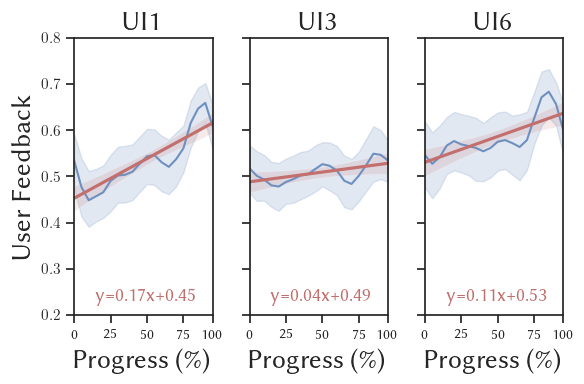

In [22]:
def draw_direct_utility_progress(domain):
    colors = ['#6e90bf', '#c26f6d']
    df_pointwise_rating_progress_domain = df_pointwise_rating_progress.groupby(['userID', 'domain', 'iteration']).mean().reset_index()
    df_listwise_rating_progress_domain = df_listwise_rating_progress.groupby(['userID', 'domain', 'iteration']).mean().reset_index()
    df_listwise_ranking_progress_domain = df_listwise_ranking_progress.groupby(['userID', 'domain', 'iteration']).mean().reset_index()

    df_pointwise_rating_progress_domain = df_pointwise_rating_progress[df_pointwise_rating_progress.domain == domain].dropna()
    df_listwise_rating_progress_domain = df_listwise_rating_progress[df_listwise_rating_progress.domain == domain].dropna()
    df_listwise_ranking_progress_domain = df_listwise_ranking_progress[df_listwise_ranking_progress.domain == domain].dropna()

    slope, intercept, r_value, p_value, std_err = stats.linregress(df_pointwise_rating_progress_domain['iteration'], df_pointwise_rating_progress_domain['utility'])
    fig, axes = plt.subplots(1, 3, figsize=(6, 4))
    sns.lineplot(ax=axes[0], data=df_pointwise_rating_progress_domain, x='iteration', y='utility', color=colors[0])
    sns.regplot(ax=axes[0], data=df_pointwise_rating_progress_domain, x='iteration', y='utility', scatter=False, color=colors[-1], order=1)
    axes[0].set_xticks([0, 5, 10, 15, 19])
    axes[0].set_xlim(0, 19)
    axes[0].set_xticklabels([0, int(500/20), int(1000/20), int(1500/20), 100])
    axes[0].set_ylabel('User Feedback', fontsize=20)
    axes[0].annotate('y={:.2f}x+{:.2f}'.format(slope*20, intercept), xy=(0.15, 0.05), xycoords='axes fraction', fontsize=14, color=colors[-1])

    slope, intercept, r_value, p_value, std_err = stats.linregress(df_listwise_rating_progress_domain['iteration'], df_listwise_rating_progress_domain['utility'])
    sns.lineplot(ax=axes[1], data=df_listwise_rating_progress_domain, x='iteration', y='utility', color=colors[0])
    sns.regplot(ax=axes[1], data=df_listwise_rating_progress_domain, x='iteration', y='utility', scatter=False, color=colors[-1], order=1)
    axes[1].set_xticks([0, 5, 10, 15, 19])
    axes[1].set_xlim(0, 19)
    axes[1].set_xticklabels([0, int(500/20), int(1000/20), int(1500/20), 100])
    axes[1].set_ylabel('')
    axes[1].set_yticklabels([])
    axes[1].annotate('y={:.2f}x+{:.2f}'.format(slope*20, intercept), xy=(0.15, 0.05), xycoords='axes fraction', fontsize=14, color=colors[-1])

    slope, intercept, r_value, p_value, std_err = stats.linregress(df_listwise_ranking_progress_domain['iteration'], df_listwise_ranking_progress_domain['utility'])
    sns.lineplot(ax=axes[2], data=df_listwise_ranking_progress_domain, x='iteration', y='utility', color=colors[0])
    sns.regplot(ax=axes[2], data=df_listwise_ranking_progress_domain, x='iteration', y='utility', scatter=False, color=colors[-1], order=1)
    axes[2].set_xticks([0, 5, 10, 15, 19])
    axes[2].set_xlim(0, 19)
    axes[2].set_xticklabels([0, int(500/20), int(1000/20), int(1500/20), 100])
    axes[2].set_ylabel('')
    axes[2].set_yticklabels([])
    axes[2].annotate('y={:.2f}x+{:.2f}'.format(slope*20, intercept), xy=(0.15, 0.05), xycoords='axes fraction', fontsize=14, color=colors[-1])

    axes[0].set_xlabel('Progress (\%)', fontsize=20)
    axes[1].set_xlabel('Progress (\%)', fontsize=20)
    axes[2].set_xlabel('Progress (\%)', fontsize=20)
    axes[0].set_title('UI1', fontsize=20)
    axes[1].set_title('UI3', fontsize=20)
    axes[2].set_title('UI6', fontsize=20)
    axes[0].set_xlim(0, 19)
    axes[1].set_xlim(0, 19)
    axes[2].set_xlim(0, 19)
    axes[0].set_ylim(.2, .8)
    axes[1].set_ylim(.2, .8)
    axes[2].set_ylim(.2, .8)

    plt.tight_layout()
    plt.savefig('figures/utility_direct_progress_{}.pdf'.format(domain), bbox_inches='tight')

draw_direct_utility_progress('text')

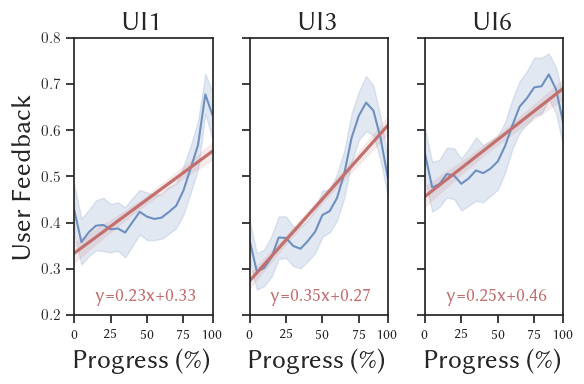

In [23]:
draw_direct_utility_progress('image')